Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 26, 26, 5)      │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 13, 13, 5)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 11, 11, 10)     │           460 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 5, 5, 10)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flat (Flatten)                  │ (None, 250)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop (Dropout)                  │ (None, 250)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 128)            │        32,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense2 (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,928 (132.53 KB)

 Trainable params: 33,928 (132.53 KB)

 Non-trainable params: 0 (0.00 B)

CNN Design 1: None
Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.8754 - loss: 0.3885 - val_accuracy: 0.9686 - val_loss: 0.1047
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9425 - loss: 0.1814 - val_accuracy: 0.9748 - val_loss: 0.0777
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9523 - loss: 0.1490 - val_accuracy: 0.9790 - val_loss: 0.0627
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9574 - loss: 0.1300 - val_accuracy: 0.9823 - val_loss: 0.0513
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9627 - loss: 0.1150 - val_accuracy: 0.9833 - val_loss: 0.0487
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9852 - loss: 0.0485
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9833 - loss: 0.0487
Final train accuracy: 0.9852166771888733
Final test accuracy: 0.983299970626831


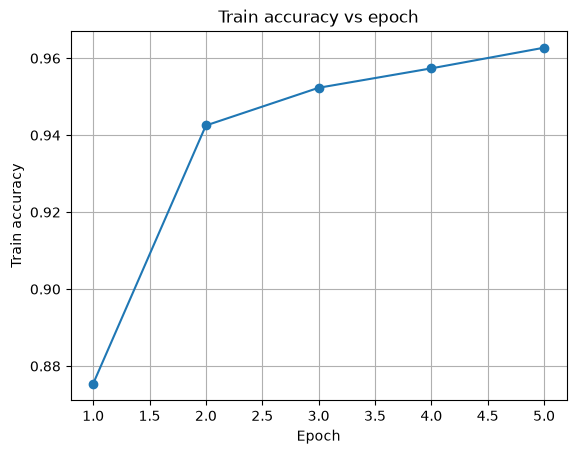

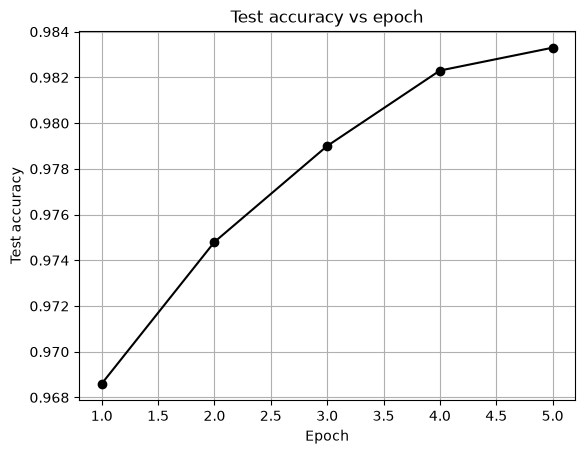

In [1]:
import tensorflow as tf
import numpy as np
from tensorflow.keras import layers, models, optimizers
mnist = tf.keras.datasets.mnist
(x_train,y_train) , (x_test,y_test) = mnist.load_data()
#reshape and normalization
# -1 is used to divide total elements by known dimensions to get the sample count
x_train = x_train.reshape(-1,28,28,1).astype("float32")/255
x_test = x_test.reshape(-1,28,28,1).astype("float32")/255
#one hot encoding
y_train=tf.keras.utils.to_categorical(y_train, num_classes=10)
y_test=tf.keras.utils.to_categorical(y_test, num_classes=10)
# Setting up CNN 1 Design
inputs = layers.Input(shape=(28, 28, 1))
x1 = layers.Conv2D(5, kernel_size=(3, 3), activation='relu', name='conv1')(inputs)
x2 = layers.MaxPooling2D(pool_size=(2, 2), name='pool1')(x1)
x3 = layers.Conv2D(10, kernel_size=(3, 3), activation='relu', name='conv2')(x2)
x4 = layers.MaxPooling2D(pool_size=(2, 2), name='pool2')(x3)
x5 = layers.Flatten(name='flat')(x4)
x6 = layers.Dropout(0.45, name='drop')(x5)
x7 = layers.Dense(128, activation='relu', name='dense1')(x6)
outputs = layers.Dense(10, activation='softmax', name='dense2')(x7)
CNN1 = models.Model(inputs=inputs, outputs=outputs)
print('CNN Design 1:' ,CNN1.summary())
# code to train CNN 1
adam = optimizers.Adam(learning_rate=0.001)
CNN1.compile(loss=tf.keras.losses.categorical_crossentropy, optimizer=adam, metrics=['accuracy'])
previous=CNN1.fit(x_train,y_train,epochs=5,validation_data=(x_test,y_test))
train_loss, train_acc=CNN1.evaluate(x_train,y_train)
test_loss, test_acc=CNN1.evaluate(x_test,y_test)
print('Final train accuracy:',train_acc )
print('Final test accuracy:',test_acc )
epochs = range(1,6)

import matplotlib.pyplot as plt
plt.figure()
plt.plot(epochs, previous.history['accuracy'], marker='o')
plt.xlabel('Epoch')
plt.ylabel('Train accuracy')
plt.title('Train accuracy vs epoch')
plt.grid(True)
plt.show()

plt.figure()
plt.plot(epochs, previous.history['val_accuracy'], marker='o', color='black')
plt.xlabel('Epoch')
plt.ylabel('Test accuracy')
plt.title('Test accuracy vs epoch')
plt.grid(True)
plt.show()


In [ ]:
weight_conv1, biases_conv1 = CNN1.get_layer('conv1').get_weights()
weight_conv2, biases_conv2 = CNN1.get_layer('conv2').get_weights()
weight_dense1, biases_dense1 = CNN1.get_layer('dense1').get_weights()
weight_dense2, biases_dense2 = CNN1.get_layer('dense2').get_weights()
def quantize_int8(num,scale):
    q = np.round(num * (scale))
    return np.clip(q, -128, 127).astype(np.int8)
w_conv1_q = quantize_int8(weight_conv1.reshape(-1,5),2**7)
w_conv2_q = quantize_int8(weight_conv2.reshape(-1,10),2**7)
w_dense1_q = quantize_int8(weight_dense1,2**7)
w_dense2_q = quantize_int8(weight_dense2,2**7)
b_conv1_q = np.round(biases_conv1 * (2**13)).astype(np.int32) #input+weight
b_conv2_q = np.round(biases_conv2 * (2**13)).astype(np.int32) 
b_dense1_q = np.round(biases_dense1 * (2**13)).astype(np.int32) 
b_dense2_q = np.round(biases_dense2 * (2**13)).astype(np.int32) 
y_test_labels = np.argmax(y_test, axis=1)
selected_indices = []
for digit in range(10):
    idx = np.where(y_test_labels == digit)[0][:10]
    selected_indices.extend(idx)
x_test_100 = x_test[selected_indices]
y_test_100 = y_test_labels[selected_indices]
x_test_100_q = quantize_int8(x_test_100,2**6)

def im2col(img, k=3):
    H, W, C = img.shape
    out_h, out_w = H - k + 1, W - k + 1
    patches = []
    for i in range(out_h):
        for j in range(out_w):
            patches.append(img[i:i+k, j:j+k, :].reshape(-1)) # reshape to result in 2D matrix
    return np.array(patches, dtype=np.int32)
def maxpool2x2(arr):
    H, W, C = arr.shape
    out = np.zeros((H // 2, W // 2, C), dtype=np.int32)
    for i in range(0, H - 1, 2):
        for j in range(0, W - 1, 2):
            out[i // 2, j // 2, :] = np.max(arr[i:i+2, j:j+2, :], axis=(0, 1))
    return out
correct = 0
for n in range(100):
    # Conv1 - (676 x 9) X (9 x 5) gives (26, 26, 5)
    col1 = im2col(x_test_100_q[n], k=3)
    c1 = (col1 @ w_conv1_q.astype(np.int32)) + b_conv1_q
    c1 = np.clip(c1 >> 7, 0, 127)
    p1 = maxpool2x2(c1.reshape(26, 26, 5))      # (13, 13, 5)

    # Conv2 - (121 x 45) X (45 x 10) gives (11, 11, 10)
    col2 = im2col(p1, k=3)
    c2 = (col2 @ w_conv2_q.astype(np.int32)) + b_conv2_q
    c2 = np.clip(c2 >> 7, 0, 127)     
    p2 = maxpool2x2(c2.reshape(11, 11, 10))     # (5, 5, 10)

    # Flatten Dense1 - (1 x 250) X (250 x 128)
    flat = p2.reshape(1, -1)
    d1 = (flat @ w_dense1_q.astype(np.int32)) + b_dense1_q
    d1 = np.clip(d1 >> 7, 0, 127)     

    # Dense2 - (1 x 128) X (128 x 10) gives argmax
    d2 = (d1 @ w_dense2_q.astype(np.int32)) + b_dense2_q
    pred = np.argmax(d2)

    if pred == y_test_100[n]:
        correct += 1
print("Quantized Accuracy (100 samples):", correct,"%")

np.savetxt("w_conv1.txt", w_conv1_q.flatten(), fmt="%d")
np.savetxt("b_conv1.txt", b_conv1_q.flatten(), fmt="%d")
np.savetxt("w_conv2.txt", w_conv2_q.flatten(), fmt="%d")
np.savetxt("b_conv2.txt", b_conv2_q.flatten(), fmt="%d")
np.savetxt("w_dense1.txt", w_dense1_q.flatten(), fmt="%d")
np.savetxt("b_dense1.txt", b_dense1_q.flatten(), fmt="%d")
np.savetxt("w_dense2.txt", w_dense2_q.flatten(), fmt="%d")
np.savetxt("b_dense2.txt", b_dense2_q.flatten(), fmt="%d")
np.savetxt("test_images_100.txt", x_test_100_q.flatten(), fmt="%d")
np.savetxt("test_labels_100.txt", y_test_100.flatten(), fmt="%d")

Quantized Integer Inference Accuracy (100 samples): 98 %


In [3]:
import os
os.makedirs("modelsim_data", exist_ok=True)
OUT = "modelsim_data"
max_acc = 0

def export_layer(name, A, B):
    """Pad A rows / B cols to multiples of 4, save A, B, dims, golden. Returns unpadded A@B."""
    global max_acc
    M, K = A.shape
    N = B.shape[1]
    Ap = np.pad(A, ((0, (-M) % 4), (0, 0))).astype(np.int64)
    Bp = np.pad(B, ((0, 0), (0, (-N) % 4))).astype(np.int64)
    G = Ap @ Bp
    max_acc = max(max_acc, int(np.abs(G).max()))
    np.savetxt(f"{OUT}/{name}_A.txt", Ap.flatten(), fmt="%d")
    np.savetxt(f"{OUT}/{name}_B.txt", Bp.flatten(), fmt="%d")
    np.savetxt(f"{OUT}/{name}_dims.txt", [Ap.shape[0], Ap.shape[1], Bp.shape[1]], fmt="%d")
    np.savetxt(f"{OUT}/{name}_golden.txt", G.flatten(), fmt="%d")
    print(f"{name}: A {Ap.shape} x B {Bp.shape}, tiles = {(Ap.shape[0]//4)*(Bp.shape[1]//4)}")
    return G[:M, :N]

NIMG = 100

# ---- conv1: (100*676 x 9) @ (9 x 5) ----
A1 = np.vstack([im2col(x_test_100_q[n]) for n in range(NIMG)])
G1 = export_layer("conv1", A1, w_conv1_q)
c1 = np.clip((G1 + b_conv1_q) >> 7, 0, 127).reshape(NIMG, 26, 26, 5)
p1 = np.stack([maxpool2x2(c1[n]) for n in range(NIMG)])            # (100,13,13,5)

# ---- conv2: (100*121 x 45) @ (45 x 10) ----
A2 = np.vstack([im2col(p1[n]) for n in range(NIMG)])
G2 = export_layer("conv2", A2, w_conv2_q)
c2 = np.clip((G2 + b_conv2_q) >> 7, 0, 127).reshape(NIMG, 11, 11, 10)
p2 = np.stack([maxpool2x2(c2[n]) for n in range(NIMG)])            # (100,5,5,10)

# ---- dense1: (100 x 250) @ (250 x 128) ----
A3 = p2.reshape(NIMG, -1)
G3 = export_layer("dense1", A3, w_dense1_q)
d1 = np.clip((G3 + b_dense1_q) >> 7, 0, 127)                       # (100,128)

# ---- dense2: (100 x 128) @ (128 x 10) ----
G4 = export_layer("dense2", d1, w_dense2_q)
logits = G4 + b_dense2_q
pred = np.argmax(logits, axis=1)

# ---- labels, expected predictions, biases ----
np.savetxt(f"{OUT}/test_labels_100.txt", y_test_100, fmt="%d")
np.savetxt(f"{OUT}/expected_pred_100.txt", pred, fmt="%d")
np.savetxt(f"{OUT}/b_dense2.txt", b_dense2_q, fmt="%d")

print("\nNumPy integer accuracy:", np.sum(pred == y_test_100), "/ 100")
print("Largest |accumulator| over all layers:", max_acc,
      "-> needs", int(np.ceil(np.log2(max_acc + 1))) + 1, "signed bits for cout")

conv1: A (67600, 9) x B (9, 8), tiles = 33800
conv2: A (12100, 45) x B (45, 12), tiles = 9075
dense1: A (100, 250) x B (250, 128), tiles = 800
dense2: A (100, 128) x B (128, 12), tiles = 75

NumPy integer accuracy: 98 / 100
Largest |accumulator| over all layers: 89651 -> needs 18 signed bits for cout


In [4]:
import os
print(os.path.abspath("modelsim_data"))

d:\Quartus\EE224\project\modelsim_data


In [5]:
print(weight_conv1.min(), weight_conv1.max())
#multiply by 2^7 to get the output in the range [-128,127]
#test has range from 0 to 1.0 so use 2**6

-0.57346034 0.66281056
